<a href="https://colab.research.google.com/github/vandau16/THXDMHTTNT/blob/main/TUAN%203/Bai_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÀI 1 — HOÀN THÀNH CÁC BÀI TẬP TRONG NOTEBOOK MẪU

Notebook này chỉ giải **Bài 1** trong slide: thực hiện các bài tập về class imbalance, KFold/StratifiedKFold, số fold, sampling và classifier trên dữ liệu Breast Cancer.

## PHẦN A — THƯ VIỆN VÀ CẤU HÌNH

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, PrecisionRecallDisplay, make_scorer
)
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

def cv_summary(model, X_data, y_data, cv):
    scores = cross_validate(model, X_data, y_data, cv=cv, scoring=scoring)
    result = {}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        result[f"{metric}_mean"] = values.mean()
        result[f"{metric}_std"] = values.std()
    return result
# Cấu hình giao diện biểu đồ đồng nhất (kiểu báo cáo học thuật sạch, lưới ngang mờ, bỏ viền trên/phải)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#EAEAEA",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "font.size": 10.5,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": False,
    "legend.fontsize": 10
})

PALETTE_MAIN = ["#31708E", "#9CB4C2", "#B57B56", "#5E8B7E"]

def style_ax(ax, grid_axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, axis=grid_axis, color="#EAEAEA", linewidth=0.7)
    ax.set_axisbelow(True)
    return ax

# BÀI 1 — HOÀN THÀNH CÁC BÀI TẬP TRONG NOTEBOOK MẪU

## 1. Chuẩn bị dữ liệu Breast Cancer

Giữ toàn bộ mẫu Benign và lấy số lượng Malignant theo từng kịch bản: 40, 60, 120 và toàn bộ dữ liệu gốc. Trường hợp 60 là mức ban đầu trong notebook mẫu; thêm vào để tiện đối chiếu.

In [2]:
cancer = load_breast_cancer(as_frame=True)
X_full = cancer.data.copy()
y_full = (cancer.target == 0).astype(int)  # 1 = malignant, 0 = benign

df_full = X_full.copy()
df_full["target"] = y_full

benign_df = df_full[df_full["target"] == 0]
malignant_df = df_full[df_full["target"] == 1]

print("Dữ liệu gốc:", df_full.shape)
print("Benign:", len(benign_df), "| Malignant:", len(malignant_df))
display(df_full.head())

Dữ liệu gốc: (569, 31)
Benign: 357 | Malignant: 212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## Bài 1.1 — Mức độ imbalance

Thay số mẫu Malignant thành 40, 120 và toàn bộ dữ liệu gốc. Dùng cùng Logistic Regression có StandardScaler, cùng tỷ lệ train/test và đánh giá trên tập test. So sánh Accuracy, Recall, F1 và PR-AUC.

**Nhận xét:** Khi số mẫu Malignant tăng, mô hình có thêm ví dụ để học lớp dương. Tuy nhiên kết quả cụ thể phụ thuộc lần chia dữ liệu và cấu trúc mẫu; cần căn cứ vào bảng kết quả chạy thực tế.

In [3]:
def make_breast_dataset(n_malignant=None):
    if n_malignant is None:
        malignant_part = malignant_df.copy()
    else:
        malignant_part = malignant_df.sample(
            n=min(n_malignant, len(malignant_df)),
            random_state=RANDOM_STATE
        )
    data = pd.concat([benign_df, malignant_part], axis=0)
    return data.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

imbalance_scenarios = {
    "Malignant = 40": 40,
    "Malignant = 60 (baseline)": 60,
    "Malignant = 120": 120,
    "Toàn bộ dữ liệu gốc": None
}

imbalance_results = []
for scenario, n_pos in imbalance_scenarios.items():
    data = make_breast_dataset(n_pos)
    X = data.drop(columns="target")
    y = data["target"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    imbalance_results.append({
        "Kịch bản": scenario,
        "Số mẫu": len(data),
        "Malignant trong dữ liệu": int(y.sum()),
        "Accuracy": accuracy_score(y_test, pred),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, prob)
    })

imbalance_table = pd.DataFrame(imbalance_results).set_index("Kịch bản")
display(imbalance_table.round(4))

,Số mẫu,Malignant trong dữ liệu,Accuracy,Recall,F1,PR-AUC
Kịch bản,,,,,,
Malignant = 40,397,40,1.0000,1.0000,1.0000,1.0000
Malignant = 60 (baseline),417,60,0.9881,0.9167,0.9565,0.9936
Malignant = 120,477,120,0.9688,0.9167,0.9362,0.9567
Toàn bộ dữ liệu gốc,569,212,0.9649,0.9286,0.9512,0.9888


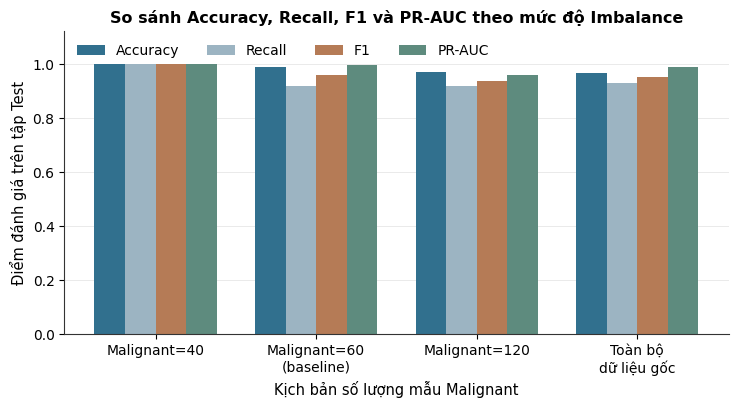

In [4]:
# Biểu đồ minh họa Bài 1.1: So sánh các metric theo mức độ imbalance
fig, ax = plt.subplots(figsize=(7.5, 4.2))
metrics_1_1 = ["Accuracy", "Recall", "F1", "PR-AUC"]
x = np.arange(len(imbalance_table.index))
width = 0.19

for i, m in enumerate(metrics_1_1):
    offset = (i - (len(metrics_1_1) - 1) / 2) * width
    ax.bar(x + offset, imbalance_table[m], width, label=m, color=PALETTE_MAIN[i])

ax.set_xticks(x)
ax.set_xticklabels(["Malignant=40", "Malignant=60\n(baseline)", "Malignant=120", "Toàn bộ\ndữ liệu gốc"])
ax.set_ylabel("Điểm đánh giá trên tập Test")
ax.set_xlabel("Kịch bản số lượng mẫu Malignant")
ax.set_ylim(0, 1.12)
ax.legend(ncol=4, loc="upper left")
style_ax(ax, "y")
plt.title("So sánh Accuracy, Recall, F1 và PR-AUC theo mức độ Imbalance")
plt.tight_layout()
plt.show()

**Kết luận Bài 1.1:** Không nên kết luận mô hình tốt chỉ vì Accuracy cao. Khi lớp Malignant ít, cần đặc biệt theo dõi Recall và PR-AUC vì bỏ sót mẫu Malignant là lỗi đáng quan tâm.

## Bài 1.2 — So sánh KFold và StratifiedKFold

Dùng cùng Logistic Regression và cùng tập dữ liệu mất cân bằng có 60 mẫu Malignant. So sánh mean và standard deviation của các metric trên 5 folds.

In [5]:
data_60 = make_breast_dataset(60)
X = data_60.drop(columns="target")
y = data_60["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

cv_compare = pd.DataFrame({
    "KFold": cv_summary(baseline, X_train, y_train, kfold),
    "StratifiedKFold": cv_summary(baseline, X_train, y_train, stratified_kfold)
}).T
display(cv_compare.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
KFold,0.988,0.0112,1.0000,0.0000,0.9012,0.1052,0.9446,0.0613,0.9975,0.0042,0.9891,0.0188
StratifiedKFold,0.985,0.0164,0.9618,0.0469,0.9400,0.1200,0.9447,0.0646,0.9951,0.0098,0.9855,0.0291


In [6]:
def fold_class_distribution(cv, X_data, y_data, cv_name):
    rows = []
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_data, y_data), 1):
        y_val = y_data.iloc[val_idx]
        rows.append({
            "CV": cv_name,
            "Fold": fold,
            "Validation size": len(val_idx),
            "Malignant validation": int(y_val.sum()),
            "Malignant rate (%)": round(y_val.mean() * 100, 2)
        })
    return rows

fold_dist = pd.DataFrame(
    fold_class_distribution(kfold, X_train, y_train, "KFold") +
    fold_class_distribution(stratified_kfold, X_train, y_train, "StratifiedKFold")
)
display(fold_dist)

,CV,Fold,Validation size,Malignant validation,Malignant rate (%)
0,KFold,1,67,7,10.45
1,KFold,2,67,10,14.93
2,KFold,3,67,12,17.91
3,KFold,4,66,11,16.67
4,KFold,5,66,8,12.12
5,StratifiedKFold,1,67,10,14.93
6,StratifiedKFold,2,67,10,14.93
7,StratifiedKFold,3,67,10,14.93
8,StratifiedKFold,4,66,9,13.64
9,StratifiedKFold,5,66,9,13.64


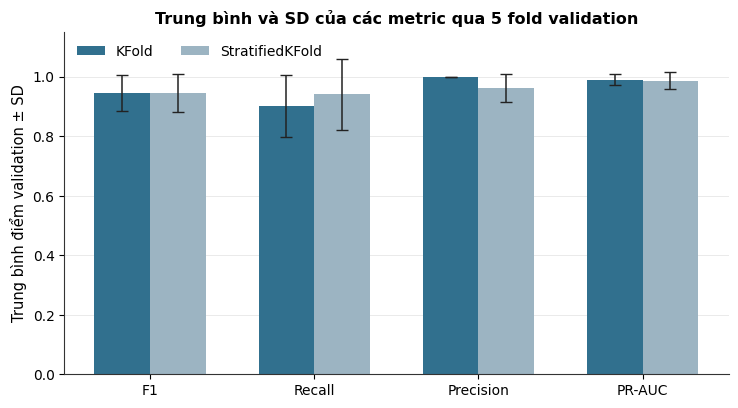

In [7]:
# Biểu đồ minh họa Bài 1.2: Trung bình và SD của các metric qua 5 fold validation (giống Hình 2)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
metrics_1_2 = ["f1", "recall", "precision", "pr_auc"]
labels_1_2 = ["F1", "Recall", "Precision", "PR-AUC"]
x = np.arange(len(metrics_1_2))
width = 0.34

kf_means = [cv_compare.loc["KFold", f"{m}_mean"] for m in metrics_1_2]
kf_stds  = [cv_compare.loc["KFold", f"{m}_std"]  for m in metrics_1_2]
skf_means = [cv_compare.loc["StratifiedKFold", f"{m}_mean"] for m in metrics_1_2]
skf_stds  = [cv_compare.loc["StratifiedKFold", f"{m}_std"]  for m in metrics_1_2]

ax.bar(x - width/2, kf_means, width, yerr=kf_stds, capsize=4,
       label="KFold", color="#31708E", error_kw=dict(ecolor="#222222", lw=1.1))
ax.bar(x + width/2, skf_means, width, yerr=skf_stds, capsize=4,
       label="StratifiedKFold", color="#9CB4C2", error_kw=dict(ecolor="#222222", lw=1.1))

ax.set_xticks(x)
ax.set_xticklabels(labels_1_2)
ax.set_ylabel("Trung bình điểm validation ± SD")
ax.set_ylim(0.0, 1.15)
ax.legend(ncol=2, loc="upper left")
style_ax(ax, "y")
plt.title("Trung bình và SD của các metric qua 5 fold validation")
plt.tight_layout()
plt.show()

**Giải thích:** KFold chia dữ liệu thành các phần mà không ràng buộc tỷ lệ lớp, nên với dữ liệu imbalance, tỷ lệ Malignant ở từng fold có thể chênh lệch. StratifiedKFold cố gắng giữ tỷ lệ lớp tương tự toàn bộ dữ liệu ở mỗi fold. Nhờ đó, các fold thường đại diện hơn và kết quả đánh giá thường ổn định hơn. Đây là xu hướng, không phải bảo đảm mọi metric trong mọi lần chạy đều có độ lệch chuẩn thấp hơn.

## Bài 1.3 — Thay đổi số fold: K = 3, 5, 10

In [8]:
fold_results = []
for k in [3, 5, 10]:
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    result = cv_summary(baseline, X_train, y_train, cv)
    result["K"] = k
    fold_results.append(result)

fold_table = pd.DataFrame(fold_results).set_index("K")
display(fold_table.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
K,,,,,,,,,,,,
3,0.988,0.0042,1.0000,0.0000,0.9167,0.0295,0.9563,0.0162,0.9971,0.0040,0.9907,0.0132
5,0.985,0.0164,0.9618,0.0469,0.9400,0.1200,0.9447,0.0646,0.9951,0.0098,0.9855,0.0291
10,0.988,0.0147,0.9667,0.0667,0.9550,0.0907,0.9564,0.0550,0.9957,0.0129,0.9861,0.0417


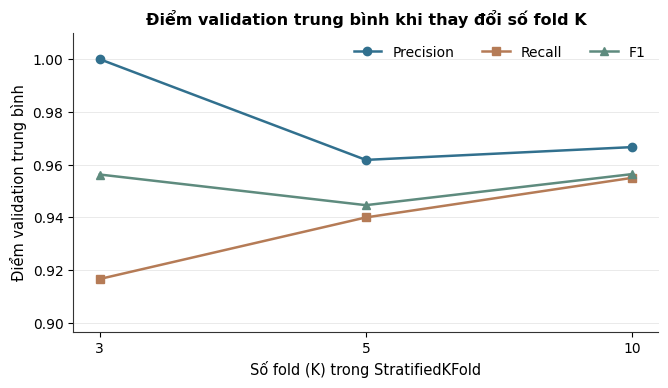

In [9]:
# Biểu đồ minh họa Bài 1.3: Biến thiên điểm validation trung bình theo số fold K
fig, ax = plt.subplots(figsize=(6.8, 4.0))
k_vals = fold_table.index.astype(str)

ax.plot(k_vals, fold_table["precision_mean"], marker="o", linewidth=1.8, markersize=6,
        color="#31708E", label="Precision")
ax.plot(k_vals, fold_table["recall_mean"], marker="s", linewidth=1.8, markersize=6,
        color="#B57B56", label="Recall")
ax.plot(k_vals, fold_table["f1_mean"], marker="^", linewidth=1.8, markersize=6,
        color="#5E8B7E", label="F1")

ax.set_xlabel("Số fold (K) trong StratifiedKFold")
ax.set_ylabel("Điểm validation trung bình")
ymin = min(fold_table[["precision_mean", "recall_mean", "f1_mean"]].min()) - 0.02
ymax = min(1.01, max(fold_table[["precision_mean", "recall_mean", "f1_mean"]].max()) + 0.02)
ax.set_ylim(max(0, ymin), ymax)
ax.legend(ncol=3, loc="upper right")
style_ax(ax, "y")
plt.title("Điểm validation trung bình khi thay đổi số fold K")
plt.tight_layout()
plt.show()

**Nhận xét:** Tăng K thường làm mỗi lần huấn luyện sử dụng phần lớn dữ liệu train hơn, nhưng chi phí tính toán tăng. Mean score có thể thay đổi nhẹ; standard deviation phản ánh biến động giữa các fold. Không có K tối ưu cho mọi bộ dữ liệu.

## Bài 1.4 — Thay đổi mức Over-Sampling

Thử sampling_strategy bằng 0.5, 0.75 và 1.0. Sampling được đặt bên trong imbalanced-learn Pipeline để chỉ áp dụng lên training fold.

In [10]:
over_results = []
for ratio in [0.5, 0.75, 1.0]:
    model = ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(sampling_strategy=ratio, random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ])
    result = cv_summary(model, X_train, y_train, stratified_kfold)
    result["sampling_strategy"] = ratio
    over_results.append(result)

over_table = pd.DataFrame(over_results).set_index("sampling_strategy")
display(over_table.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
sampling_strategy,,,,,,,,,,,,
0.50,0.988,0.0112,0.9618,0.0469,0.96,0.08,0.9577,0.0411,0.9947,0.0097,0.9836,0.0284
0.75,0.988,0.0112,0.9618,0.0469,0.96,0.08,0.9577,0.0411,0.9951,0.0098,0.9855,0.0291
1.00,0.985,0.0094,0.9418,0.0476,0.96,0.08,0.9472,0.0353,0.9951,0.0098,0.9855,0.0291


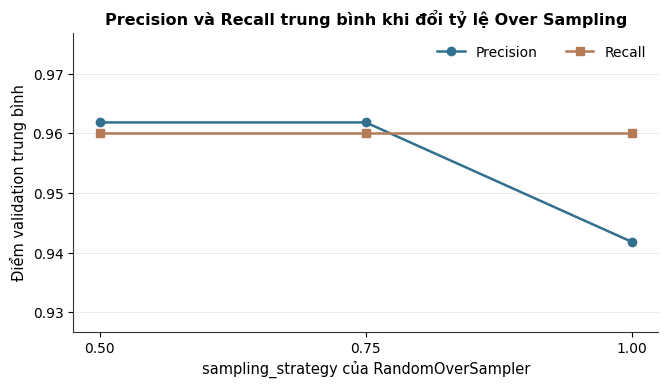

In [11]:
# Biểu đồ minh họa Bài 1.4: Precision và Recall trung bình khi đổi tỷ lệ Over Sampling (giống Hình 4)
fig, ax = plt.subplots(figsize=(6.8, 4.0))
ratios_str = [f"{r:.2f}" for r in over_table.index]

ax.plot(ratios_str, over_table["precision_mean"], marker="o", linewidth=1.8, markersize=6,
        color="#31708E", label="Precision")
ax.plot(ratios_str, over_table["recall_mean"], marker="s", linewidth=1.8, markersize=6,
        color="#B57B56", label="Recall")

ax.set_xlabel("sampling_strategy của RandomOverSampler")
ax.set_ylabel("Điểm validation trung bình")
ymin = min(over_table[["precision_mean", "recall_mean"]].min()) - 0.015
ymax = min(1.01, max(over_table[["precision_mean", "recall_mean"]].max()) + 0.015)
ax.set_ylim(max(0, ymin), ymax)
ax.legend(ncol=2, loc="upper right")
style_ax(ax, "y")
plt.title("Precision và Recall trung bình khi đổi tỷ lệ Over Sampling")
plt.tight_layout()
plt.show()

**Giải thích:** Tăng tỷ lệ oversampling làm lớp thiểu số có trọng số hiện diện lớn hơn trong quá trình học. Recall có thể tăng nhưng Precision có thể giảm do tăng False Positive. Cần chọn theo mục tiêu bài toán và quan sát F1/PR-AUC, không mặc định tỷ lệ 1.0 là tốt nhất.

## Bài 1.5 — So sánh Random Over-Sampling, Random Under-Sampling và SMOTE

In [12]:
sampling_models = {
    "No Sampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "Random Over-Sampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "Random Under-Sampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "SMOTE": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ])
}

sampling_results = []
for name, model in sampling_models.items():
    row = cv_summary(model, X_train, y_train, stratified_kfold)
    row["Model"] = name
    sampling_results.append(row)

sampling_table = pd.DataFrame(sampling_results).set_index("Model")
display(sampling_table[[
    "accuracy_mean", "precision_mean", "recall_mean",
    "f1_mean", "roc_auc_mean", "pr_auc_mean"
]].sort_values("f1_mean", ascending=False).round(4))

,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,pr_auc_mean
Model,,,,,,
SMOTE,0.9880,0.9618,0.96,0.9577,0.9947,0.9836
Random Under-Sampling,0.9849,0.9255,0.98,0.9494,0.9961,0.9895
Random Over-Sampling,0.9850,0.9418,0.96,0.9472,0.9951,0.9855
No Sampling,0.9850,0.9618,0.94,0.9447,0.9951,0.9855


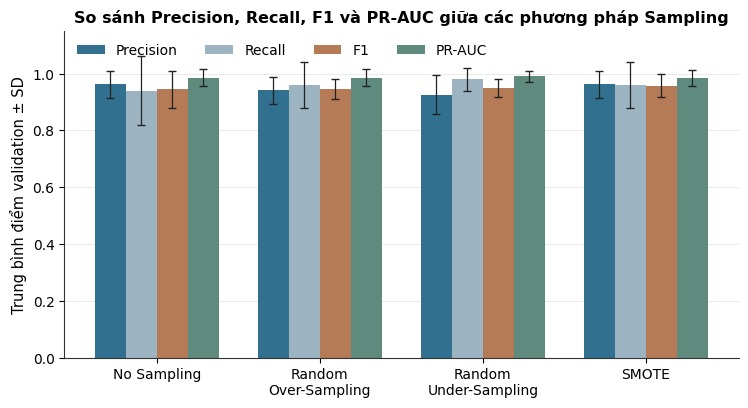

In [13]:
# Biểu đồ minh họa Bài 1.5: So sánh các phương pháp Sampling trên 5-fold CV
fig, ax = plt.subplots(figsize=(7.6, 4.2))
ordered_methods = ["No Sampling", "Random Over-Sampling", "Random Under-Sampling", "SMOTE"]
df_s = sampling_table.loc[ordered_methods]
metrics_1_5 = ["precision", "recall", "f1", "pr_auc"]
labels_1_5 = ["Precision", "Recall", "F1", "PR-AUC"]
x = np.arange(len(ordered_methods))
width = 0.19

for i, (m, lbl) in enumerate(zip(metrics_1_5, labels_1_5)):
    offset = (i - (len(metrics_1_5) - 1) / 2) * width
    ax.bar(x + offset, df_s[f"{m}_mean"], width, yerr=df_s[f"{m}_std"], capsize=3,
           label=lbl, color=PALETTE_MAIN[i], error_kw=dict(ecolor="#222222", lw=0.9))

ax.set_xticks(x)
ax.set_xticklabels(["No Sampling", "Random\nOver-Sampling", "Random\nUnder-Sampling", "SMOTE"])
ax.set_ylabel("Trung bình điểm validation ± SD")
ax.set_ylim(0, 1.15)
ax.legend(ncol=4, loc="upper left")
style_ax(ax, "y")
plt.title("So sánh Precision, Recall, F1 và PR-AUC giữa các phương pháp Sampling")
plt.tight_layout()
plt.show()

**Phân tích:** Random Over-Sampling nhân bản mẫu lớp thiểu số nên không làm mất mẫu nhưng có thể overfit. Random Under-Sampling giảm mẫu lớp đa số, giúp cân bằng nhưng có thể bỏ mất thông tin. SMOTE tạo mẫu tổng hợp dựa trên các láng giềng của lớp thiểu số; hiệu quả phụ thuộc cấu trúc dữ liệu và khoảng cách giữa các điểm. Chọn phương pháp bằng Precision, Recall, F1 và PR-AUC cùng mục tiêu thực tế.

## Bài 1.6 — Thay classifier: KNN, SVM, Decision Tree

So sánh mô hình có StandardScaler và không chuẩn hóa. Decision Tree thường ít nhạy với scale hơn KNN và SVM; KNN/SVM dựa trên khoảng cách hoặc kernel nên thường cần scale.

In [14]:
classifiers = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE)
}

classifier_results = []
for name, clf in classifiers.items():
    for scaled in [False, True]:
        steps = []
        if scaled:
            steps.append(("scaler", StandardScaler()))
        steps.append(("model", clf))
        model = Pipeline(steps)
        result = cv_summary(model, X_train, y_train, stratified_kfold)
        result["Classifier"] = name
        result["StandardScaler"] = scaled
        classifier_results.append(result)

classifier_table = pd.DataFrame(classifier_results).set_index(["Classifier", "StandardScaler"])
display(classifier_table[[
    "accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean", "pr_auc_mean"
]].round(4))

accuracy_mean  precision_mean  recall_mean  \
Classifier    StandardScaler                                               
KNN           False                  0.9640          0.9800       0.7711   
              True                   0.9851          1.0000       0.9000   
SVM           False                  0.9610          0.9550       0.7711   
              True                   0.9910          0.9818       0.9600   
Decision Tree False                  0.9730          0.8993       0.9378   
              True                   0.9730          0.8993       0.9378   

                              f1_mean  roc_auc_mean  pr_auc_mean  
Classifier    StandardScaler                                      
KNN           False            0.8578        0.9253       0.8410  
              True             0.9450        0.9796       0.9660  
SVM           False            0.8475        0.9669       0.9106  
              True             0.9683        0.9902       0.9789  
Decision Tree False            0.9104        0.9584       0.8461  
              True             0.9104        0.9584       0.8461

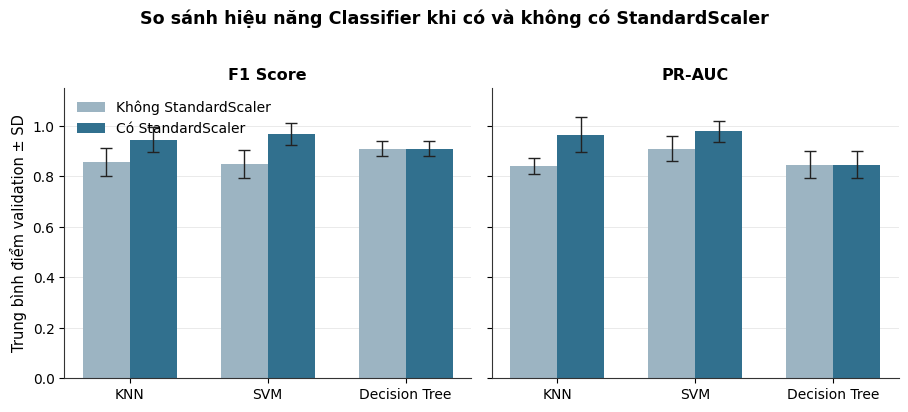

In [15]:
# Biểu đồ minh họa Bài 1.6: Ảnh hưởng của StandardScaler trên các Classifier (F1 & PR-AUC)
fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.0), sharey=True)
clf_names = ["KNN", "SVM", "Decision Tree"]
x = np.arange(len(clf_names))
width = 0.34

for ax, metric, title_m in zip(axes, ["f1", "pr_auc"], ["F1 Score", "PR-AUC"]):
    no_scale_m = [classifier_table.loc[(c, False), f"{metric}_mean"] for c in clf_names]
    no_scale_s = [classifier_table.loc[(c, False), f"{metric}_std"]  for c in clf_names]
    scale_m    = [classifier_table.loc[(c, True),  f"{metric}_mean"] for c in clf_names]
    scale_s    = [classifier_table.loc[(c, True),  f"{metric}_std"]  for c in clf_names]

    ax.bar(x - width/2, no_scale_m, width, yerr=no_scale_s, capsize=4,
           label="Không StandardScaler", color="#9CB4C2", error_kw=dict(ecolor="#222222", lw=1.0))
    ax.bar(x + width/2, scale_m, width, yerr=scale_s, capsize=4,
           label="Có StandardScaler", color="#31708E", error_kw=dict(ecolor="#222222", lw=1.0))

    ax.set_xticks(x)
    ax.set_xticklabels(clf_names)
    ax.set_title(title_m)
    ax.set_ylim(0, 1.15)
    style_ax(ax, "y")

axes[0].set_ylabel("Trung bình điểm validation ± SD")
axes[0].legend(loc="upper left")
plt.suptitle("So sánh hiệu năng Classifier khi có và không có StandardScaler", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Nhận xét:** So sánh cặp có/không StandardScaler cho từng thuật toán. KNN và SVM thường nhạy với scale; Decision Tree phân chia theo ngưỡng từng feature nên ít phụ thuộc vào đơn vị đo. Kết luận cuối cùng dựa trên bảng metric thực tế.

## Bài 1.7 — Câu hỏi suy luận

1. **Tại sao không nên sampling tập test?** Vì test phải mô phỏng phân bố dữ liệu thực tế chưa thấy. Sampling test làm thay đổi phân bố và khiến đánh giá không còn khách quan.
2. **Tại sao không fit StandardScaler trên toàn bộ dữ liệu?** Vì scaler sẽ sử dụng thông tin thống kê từ validation/test, gây data leakage. Hãy đặt scaler trong Pipeline.
3. **Khi nào Recall quan trọng hơn Precision?** Khi bỏ sót mẫu dương gây hậu quả nghiêm trọng, ví dụ sàng lọc bệnh hoặc phát hiện gian lận.
4. **Khi nào Precision quan trọng hơn Recall?** Khi dự đoán dương tính sai gây chi phí lớn, ví dụ một quy trình kiểm tra tiếp theo rất tốn kém.
5. **Vì sao PR-AUC hữu ích với dữ liệu imbalance?** Vì tập trung vào Precision và Recall của lớp dương, phản ánh rõ hơn hiệu quả nhận diện lớp thiểu số so với Accuracy đơn lẻ.
6. **Vì sao StratifiedKFold phù hợp hơn KFold?** Vì giữ tỷ lệ lớp gần tương tự giữa các fold, giúp mỗi fold đại diện hơn khi dữ liệu mất cân bằng.
7. **Random Under-Sampling có thể làm mất thông tin thế nào?** Nó loại bỏ ngẫu nhiên mẫu lớp đa số, có thể bỏ cả các mẫu quan trọng giúp mô hình học ranh giới phân lớp.
8. **SMOTE khác Random Over-Sampling ở điểm nào?** Random Over-Sampling sao chép mẫu có sẵn; SMOTE tạo mẫu tổng hợp mới bằng nội suy giữa các mẫu lớp thiểu số lân cận.